In [ ]:

import os

print(os.listdir("/content"))


['.config', 'sales_data.csv', 'ApexPlanet_DataAnalytics_Dataset (4).xlsx', 'sample_data']


In [ ]:

import pandas as pd

df = pd.read_excel(
    "/content/ApexPlanet_DataAnalytics_Dataset (4).xlsx"
)

display(df.head())
print("Dataset size:", df.shape)
print("Columns:", df.columns.tolist())


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


Dataset size: (1000, 12)
Columns: ['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']


In [ ]:

# STEP 5: DATA CLEANING

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Convert Order_Date to date format
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

# Convert numeric columns to numbers
for col in ["Age", "Quantity", "Unit_Price", "Total_Sales"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nCleaned dataset size:", df.shape)
display(df.head())


Missing values:
Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Age              20
Gender            0
City             13
Product           0
Category          0
Quantity          0
Unit_Price        0
Total_Sales       0
dtype: int64
Duplicate rows: 0

Cleaned dataset size: (1000, 12)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [ ]:

# STEP 6: KEY PERFORMANCE INDICATORS

total_sales = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_quantity = df["Quantity"].sum()
average_order_value = total_sales / total_orders

print("Total Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))


Total Sales: 139399439.65
Total Orders: 992
Total Customers: 947
Total Quantity Sold: 5435
Average Order Value: 140523.63


Sales by Category:
Category
Education      25031689.40
Electronics    50778581.70
Fashion        19835895.79
Furniture      21521561.48
Grocery        22231711.28
Name: Total_Sales, dtype: float64

Best-selling Category: Electronics


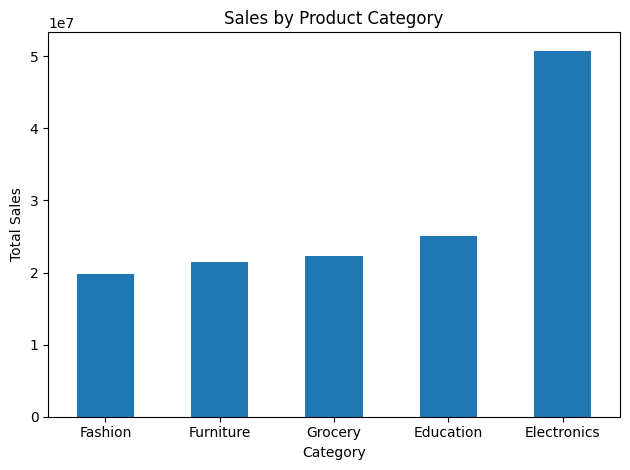

In [ ]:

# STEP 7: CATEGORY-WISE SALES ANALYSIS

category_sales = df.groupby("Category")["Total_Sales"].sum()

print("Sales by Category:")
print(category_sales)

# Find the best-selling category
print("\nBest-selling Category:",
      category_sales.idxmax())

# Create a bar chart
import matplotlib.pyplot as plt

category_sales.sort_values().plot(
    kind="bar",
    title="Sales by Product Category",
    ylabel="Total Sales",
    xlabel="Category"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Monthly Sales:
Month
2025-01    10096190.73
2025-02    11511181.46
2025-03    13059899.94
2025-04    12222700.17
2025-05    10984689.25
2025-06    12912332.64
2025-07    11746226.80
2025-08     9448471.22
2025-09     9179896.29
2025-10    12500936.50
2025-11    12627620.22
2025-12    12299904.44
2026-01      809389.99
Name: Total_Sales, dtype: float64

Highest Sales Month: 2025-03
Lowest Sales Month: 2026-01


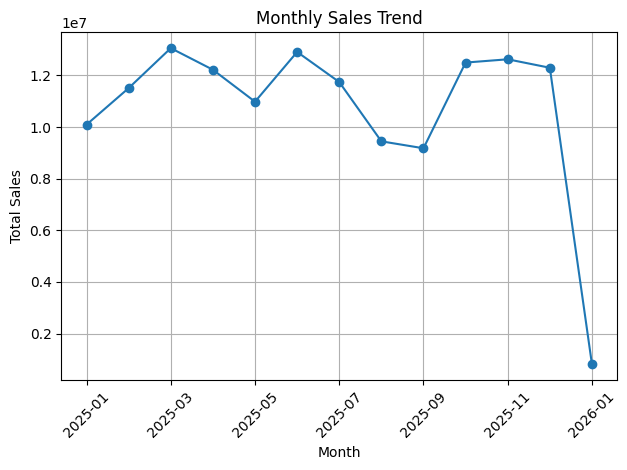

In [ ]:
# STEP 8: MONTHLY SALES ANALYSIS

df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Total_Sales"].sum()

print("Monthly Sales:")
print(monthly_sales)

print("\nHighest Sales Month:", monthly_sales.idxmax())
print("Lowest Sales Month:", monthly_sales.idxmin())

# Create monthly sales chart
import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

CUSTOMER ANALYSIS
Total Customers: 947
Repeat Customers: 52
Repeat Customer Rate: 5.49 %

TOP 10 CUSTOMERS BY SALES
Customer_ID
CUST9510    867333.24
CUST6845    769479.75
CUST6532    610981.74
CUST6082    548416.39
CUST3689    542484.08
CUST3730    538633.97
CUST4706    528036.44
CUST9693    511421.86
CUST7374    511309.40
CUST2062    493677.50
Name: Total_Sales, dtype: float64


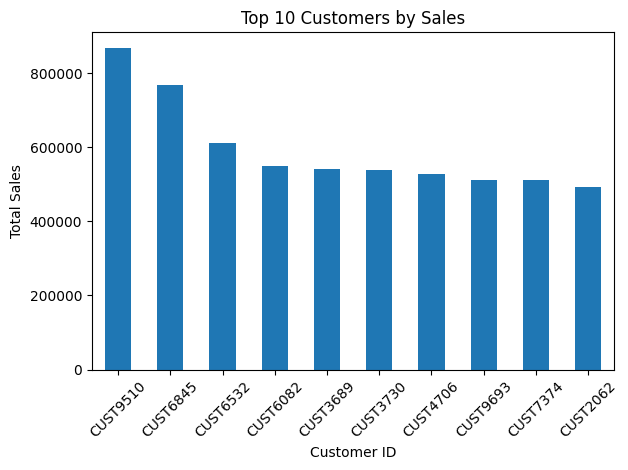

In [ ]:
# STEP 9: CUSTOMER ANALYSIS

# Total orders placed by each customer
customer_orders = df.groupby("Customer_ID")["Order_ID"].nunique()

# Identify repeat customers
repeat_customers = (customer_orders > 1).sum()

# Total unique customers
total_customers = df["Customer_ID"].nunique()

# Calculate repeat customer rate
repeat_rate = (repeat_customers / total_customers) * 100

print("CUSTOMER ANALYSIS")
print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("Repeat Customer Rate:", round(repeat_rate, 2), "%")

# Top 10 customers by sales
top_customers = (
    df.groupby("Customer_ID")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 CUSTOMERS BY SALES")
print(top_customers)

# Chart
top_customers.plot(
    kind="bar",
    title="Top 10 Customers by Sales",
    ylabel="Total Sales",
    xlabel="Customer ID"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 10: BUSINESS FINDINGS

best_category = df.groupby("Category")["Total_Sales"].sum().idxmax()

monthly_sales = df.groupby(
    df["Order_Date"].dt.to_period("M")
)["Total_Sales"].sum()

best_month = str(monthly_sales.idxmax())

customer_sales = df.groupby("Customer_ID")["Total_Sales"].sum()
top_customer = customer_sales.idxmax()

print("BUSINESS FINDINGS")
print("------------------")
print("Best-selling Category:", best_category)
print("Highest Sales Month:", best_month)
print("Top Customer ID:", top_customer)

print("\nBUSINESS RECOMMENDATIONS")
print("------------------------")
print("1. Promote products in the best-selling category.")
print("2. Study high-sales months to plan marketing campaigns.")
print("3. Reward repeat customers with loyalty offers.")
print("4. Analyze top customers to understand their preferences.")
print("5. Monitor sales trends regularly.")

BUSINESS FINDINGS
------------------
Best-selling Category: Electronics
Highest Sales Month: 2025-03
Top Customer ID: CUST9510

BUSINESS RECOMMENDATIONS
------------------------
1. Promote products in the best-selling category.
2. Study high-sales months to plan marketing campaigns.
3. Reward repeat customers with loyalty offers.
4. Analyze top customers to understand their preferences.
5. Monitor sales trends regularly.


In [10]:
df.to_csv("ApexPlanet_Cleaned_Dataset.csv", index=False)

from google.colab import files
files.download("ApexPlanet_Cleaned_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>